### **Exploratory Data Analysis of Spotify Audio Features (2000–2023)**
#### Project Overview & Objectives

This notebook presents an exploratory data analysis of 1.16 million Spotify tracks across 82 genres spanning 2000 to 2023. The primary objectives are to evaluate longitudinal trends in acoustic characteristics, establish baseline feature distributions across major genres, and evaluate structural relationships between audio characteristics and track popularity metrics.

Primary Analytical Objectives

- Longitudinal Trends: Quantify temporal shifts in acoustic characteristics (loudness, energy, acousticness, valence) across release years.

- Feature Profiling: Compare feature distributions and covariance across major genre classifications.

- Hypothesis Testing: Evaluate the correlation between musical features (such as tempo and loudness) and track popularity metrics.

### 1. Setup 

In [86]:
# --- Imports --------------------------------------------------------------
from pathlib import Path
import sys

# Works whether Jupyter starts in the project root or notebooks/ folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.visuals import set_theme, PALETTE, GREEN_DIVERGING, GREEN_SEQUENTIAL

# Initialize plot settings
set_theme()

# --- Project Paths --------------------------------------------------------
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "archive" / "spotify_data.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --- Helper Functions -----------------------------------------------------
def save_fig(fig, name):
    """Save each chart as a PNG for the README / Power BI report."""
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### 2. Data loading

Two sources are used:

* **Raw file**, `data/raw/archive/spotify_data.csv`: inspected in Section 3 exactly as downloaded. It is only ever *read*, never changed.
* **Processed files** created by `src/prepare_data.py`: the cleaned track-level data and two summary tables (`year_summary.csv`, `genre_summary.csv`).

> If the processed files are missing, run `python src/prepare_data.py` from the project folder first.

In [87]:
# Make sure the files exist before loading, with a helpful message if not.
needed = [RAW_FILE,
          PROCESSED_DIR / "spotify_clean.csv",
          PROCESSED_DIR / "year_summary.csv",
          PROCESSED_DIR / "genre_summary.csv"]
missing = [str(p) for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError("Missing files - run `python src/prepare_data.py` first:\n" + "\n".join(missing))

raw = pd.read_csv(RAW_FILE)
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw data: 1,159,764 rows x 20 columns


,Unnamed: 0,artist_name,track_name,track_id,popularity,year,genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,0,Jason Mraz,I Won't Give Up,53QF56cjZA9RTuuMZDrSA6,68,2012,acoustic,0.483,0.303,4,-10.058,1,0.0429,0.6940,0.000000,0.1150,0.139,133.406,240166,3
1,1,Jason Mraz,93 Million Miles,1s8tP3jP4GZcyHDsjvw218,50,2012,acoustic,0.572,0.454,3,-10.286,1,0.0258,0.4770,0.000014,0.0974,0.515,140.182,216387,4
2,2,Joshua Hyslop,Do Not Let Me Go,7BRCa8MPiyuvr2VU3O9W0F,57,2012,acoustic,0.409,0.234,3,-13.711,1,0.0323,0.3380,0.000050,0.0895,0.145,139.832,158960,4
3,3,Boyce Avenue,Fast Car,63wsZUhUZLlh1OsyrZq7sz,58,2012,acoustic,0.392,0.251,10,-9.845,1,0.0363,0.8070,0.000000,0.0797,0.508,204.961,304293,4
4,4,Andrew Belle,Sky's Still Blue,6nXIYClvJAfi6ujLiKqEq8,54,2012,acoustic,0.430,0.791,6,-5.419,0,0.0302,0.0726,0.019300,0.1100,0.217,171.864,244320,4


### 3. Data inspection

#### 3.1 Columns and data types

In [88]:
# One row per column: its data type, how many values are missing, and how many unique values it has.
column_overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(4),
    "unique_values": raw.nunique(),
})
column_overview

,dtype,missing,missing_%,unique_values
Unnamed: 0,int64,0,0.0000,1159764
artist_name,str,15,0.0013,64158
track_name,str,1,0.0001,882360
track_id,str,0,0.0000,1159764
popularity,int64,0,0.0000,98
year,int64,0,0.0000,24
genre,str,0,0.0000,82
danceability,float64,0,0.0000,1364
energy,float64,0,0.0000,3116
key,int64,0,0.0000,12


**What this shows**
* 20 columns: three text identifiers (`artist_name`, `track_name`, `track_id`), `genre` (text), and 16 numeric columns.
* `Unnamed: 0` is a leftover row number from an earlier export. Its values are not continuous (they go up to ~1.47M for 1.16M rows), so it carries no meaning and is dropped during cleaning.
* Missing values are rare: a handful of `artist_name` values and one `track_name`. Every numeric column is complete.

#### 3.2 Which rows have missing values?

In [89]:
# Show the rows that have any missing value
raw[raw.isna().any(axis=1)][["artist_name", "track_name", "year", "genre", "popularity"]]

,artist_name,track_name,year,genre,popularity
256971,NaN,Cold,2017,black-metal,17
256972,NaN,Wither,2017,black-metal,16
257024,NaN,Suffer,2017,black-metal,14
313028,NaN,"A World, Dead and Gray",2018,black-metal,26
313050,NaN,Hypoxic,2018,black-metal,24
313063,NaN,Bed the Cold Earth,2018,black-metal,22
313117,NaN,Life Is Long Enough,2018,black-metal,20
313153,NaN,Corroded,2018,black-metal,17
313174,NaN,Desiderate,2018,black-metal,16
313225,NaN,Where Life Should Be,2018,black-metal,15


The 15 missing artist names all belong to `black-metal` tracks from 2017–2019, and the single missing track title is a 2005 `swedish` track. Their audio features are complete, so cleaning keeps these rows and labels the missing names "Unknown".

#### 3.3 Duplicates


In [90]:
no_index = raw.drop(columns=["Unnamed: 0"])

# Lower-case, trimmed versions of artist and title catch "Song" vs "song " style near-duplicates
artist_key = no_index["artist_name"].str.lower().str.strip()
title_key = no_index["track_name"].str.lower().str.strip()

duplicate_checks = pd.Series({
    "Exact duplicate rows": no_index.duplicated().sum(),
    "Duplicate track_id": no_index["track_id"].duplicated().sum(),
    "Same artist + title (exact text)": no_index.duplicated(["artist_name", "track_name"]).sum(),
    "Same artist + title (ignoring case/spaces)": pd.DataFrame({"a": artist_key, "t": title_key}).duplicated().sum(),
}, name="rows")
duplicate_checks.to_frame()

,rows
Exact duplicate rows,0
Duplicate track_id,0
Same artist + title (exact text),0
Same artist + title (ignoring case/spaces),7868


There are **no true duplicates**: every `track_id` is unique. The ~7.9k loose matches are tracks with the same artist and title but a *different* Spotify ID, which usually means re-releases, remasters or compilation versions. They are real catalogue entries, so they are kept and recorded as a known limitation.

#### 3.4 Target Feature Validation

In [91]:
TARGET_FIELDS = ["year", "genre", "popularity", "tempo", "energy",
                 "danceability", "acousticness", "valence"]

availability = pd.DataFrame({
    "present": [f in raw.columns for f in TARGET_FIELDS],
    "dtype": [str(raw[f].dtype) for f in TARGET_FIELDS],
    "missing": [raw[f].isna().sum() for f in TARGET_FIELDS],
    "min": [raw[f].min() for f in TARGET_FIELDS],
    "max": [raw[f].max() for f in TARGET_FIELDS],
    "zeros": [(raw[f] == 0).sum() if raw[f].dtype != object and str(raw[f].dtype) != "str" else "-" for f in TARGET_FIELDS],
}, index=TARGET_FIELDS)
availability

,present,dtype,missing,min,max,zeros
year,True,int64,0,2000,2023,0
genre,True,str,0,acoustic,trip-hop,-
popularity,True,int64,0,0,100,158391
tempo,True,float64,0,0.0,249.993,1199
energy,True,float64,0,0.0,1.0,25
danceability,True,float64,0,0.0,0.993,1199
acousticness,True,float64,0,0.0,0.996,717
valence,True,float64,0,0.0,1.0,1505


In [92]:
# Zero tempo is impossible for real music. Check whether those rows also have other zeros.
zero_tempo = raw[raw["tempo"] == 0]
print(f"Rows with tempo = 0: {len(zero_tempo):,}")
print(f"  ...of which danceability = 0:   {(zero_tempo['danceability'] == 0).sum():,}")
print(f"  ...of which time_signature = 0: {(zero_tempo['time_signature'] == 0).sum():,}")
print("\nMost affected genres:")
print(zero_tempo["genre"].value_counts().head(5).to_string())

Rows with tempo = 0: 1,199
  ...of which danceability = 0:   1,199
  ...of which time_signature = 0: 1,199

Most affected genres:
genre
sleep        650
grindcore    288
classical     43
ambient       26
comedy        22


**Validation Outcome**: All eight required target fields are present with zero missing values. Two things still need handling, and `src/prepare_data.py` does both:

* **Tempo = 0 (1,199 rows):** these rows also have danceability = 0 and time signature = 0, which points to a *failed audio analysis* rather than real values. Most are `sleep` and `grindcore` tracks (ambient noise and extreme noise are hard to analyse). They are removed.
* **Popularity = 0 (~14% of rows):** a zero may mean "no data yet" rather than "unpopular". The rows are kept, but the tempo test in Section 8 is also run without them.

#### 3.5 Coverage by year and genre

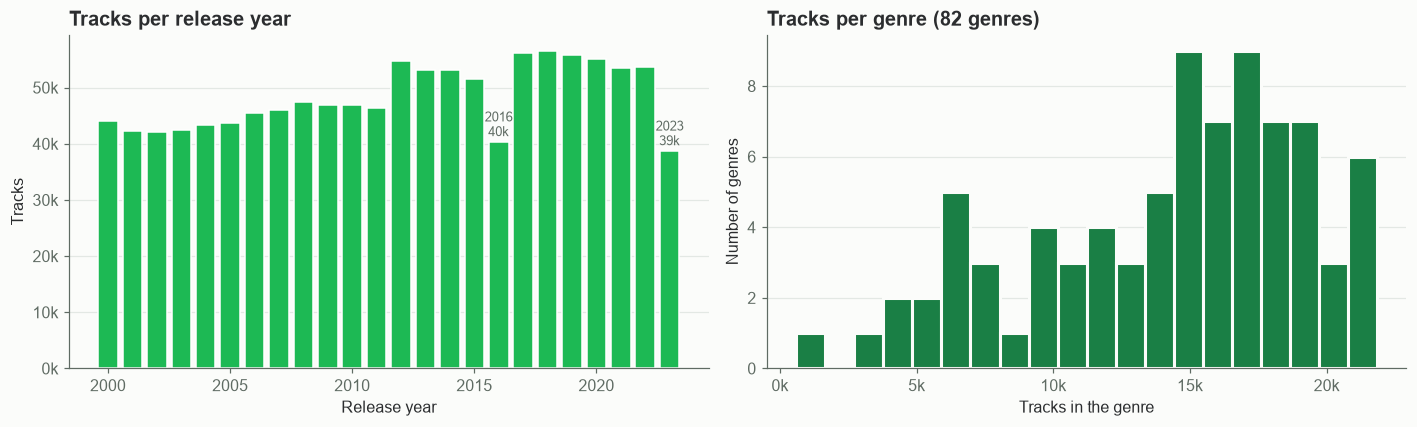

Smallest genres:
genre
detroit-techno    3920
rock              3319
songwriter         589


In [93]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Tracks per year
year_counts = raw["year"].value_counts().sort_index()
axes[0].bar(year_counts.index, year_counts.values, color=SPOTIFY_GREEN, width=0.8)
axes[0].set_title("Tracks per release year")
axes[0].set_xlabel("Release year")
axes[0].set_ylabel("Tracks")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
for yr in [2016, 2023]:   # flag the two thinner years
    axes[0].annotate(f"{yr}\n{year_counts[yr]/1000:.0f}k", (yr, year_counts[yr]),
                     xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5, color=MUTED_TEXT)

# Tracks per genre (distribution, because 82 bars would be unreadable)
genre_counts = raw["genre"].value_counts()
axes[1].hist(genre_counts.values, bins=20, color=FOREST, edgecolor=BACKGROUND, linewidth=2)
axes[1].set_title(f"Tracks per genre ({raw['genre'].nunique()} genres)")
axes[1].set_xlabel("Tracks in the genre")
axes[1].set_ylabel("Number of genres")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))

plt.tight_layout()
save_fig(fig, "01_coverage")
plt.show()

print(f"Smallest genres:\n{genre_counts.tail(3).to_string()}")

Coverage is fairly even: about 40–57k tracks per year, and most genres have 10–22k tracks. Key Dataset Limitations:

* **2016 and 2023 are thinner.** That is why the rest of this notebook compares **medians** rather than counts.
* **`songwriter` is tiny** (589 tracks). In the genre summary, groups with fewer than 30 tracks are flagged as `small_sample`.


In [94]:
clean = pd.read_csv(PROCESSED_DIR / "spotify_clean.csv")
year_summary = pd.read_csv(PROCESSED_DIR / "year_summary.csv")
genre_summary = pd.read_csv(PROCESSED_DIR / "genre_summary.csv")

del raw, no_index, artist_key, title_key   # free memory: the raw table is no longer needed

print(f"Clean data: {len(clean):,} tracks | {clean['genre'].nunique()} genres | "
      f"{clean['year'].min()}-{clean['year'].max()}")

Clean data: 1,158,536 tracks | 82 genres | 2000-2023


### 4. Feature Covariance and Correlation

Feature interactions are evaluated using Spearman rank correlation to identify monotonic dependencies while mitigating outlier impact. Redundant upper-triangle values are masked for clarity.

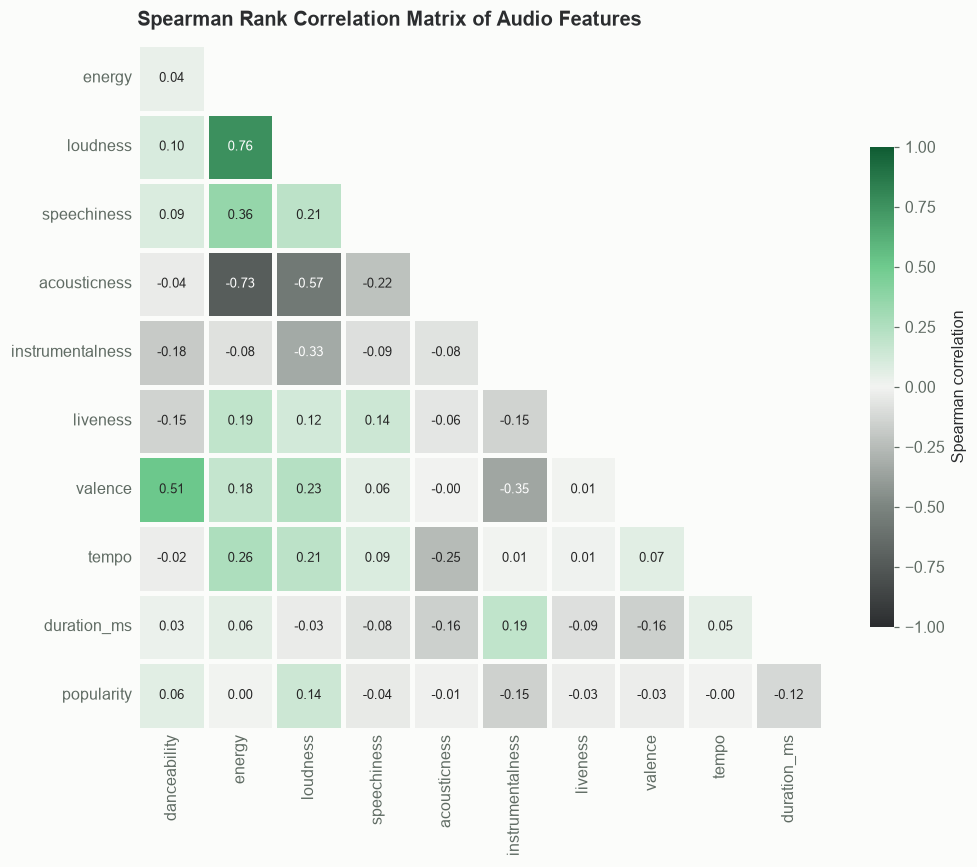

In [95]:
FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo", "duration_ms", "popularity"]

corr = clean[FEATURES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))   # True = upper triangle + diagonal (the repeated half)

# Drop the first row and last column: after masking they would be completely empty
plot_corr = corr.iloc[1:, :-1]
plot_mask = mask[1:, :-1]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(plot_corr, mask=plot_mask, cmap=GREEN_DIVERGING, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8.5},
            linewidths=2, linecolor=BACKGROUND, square=True,
            cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman Rank Correlation Matrix of Audio Features", pad=12)
ax.grid(False)
ax.tick_params(length=0)
plt.tight_layout()
save_fig(fig, "02_correlation_heatmap")
plt.show()

In [96]:
# List the strongest relationships so the chart can be read precisely
pairs = corr.where(~mask).stack().rename("rho").reset_index()
pairs["strength"] = pairs["rho"].abs()
pairs.sort_values("strength", ascending=False).head(6)[["level_0", "level_1", "rho"]] \
     .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}).round(3)

,feature_a,feature_b,rho
23,loudness,energy,0.764
45,acousticness,energy,-0.726
46,acousticness,loudness,-0.566
77,valence,danceability,0.510
34,speechiness,energy,0.358
82,valence,instrumentalness,-0.350


**Reading the Sound DNA**
* **Energy, loudness and acousticness form one cluster.** Energetic tracks are loud and *not* acoustic, so "energy vs acousticness" is close to a single axis running from **produced** to **organic** sound.
* **Valence goes with danceability:** happier-sounding tracks tend to be more danceable.
* **Popularity barely correlates with any audio feature.** The strongest links are weak: louder tracks are slightly more popular (ρ ≈ 0.14), while instrumental (ρ ≈ -0.15) and longer (ρ ≈ -0.12) tracks are slightly less popular. No single sound characteristic "makes" a hit. Keep this in mind for Section 8.

### 5. Temporal Trend Analysis: Longitudinal Feature Dynamics

#### 5.1 Energy vs acousticness

Section 4 showed energy and acousticness pulling in opposite directions. Here are their **yearly medians** from `year_summary.csv`. Both are on the same 0–1 scale, so they share **one** axis. A dual-axis chart could manufacture a "crossover" that isn't in the data.

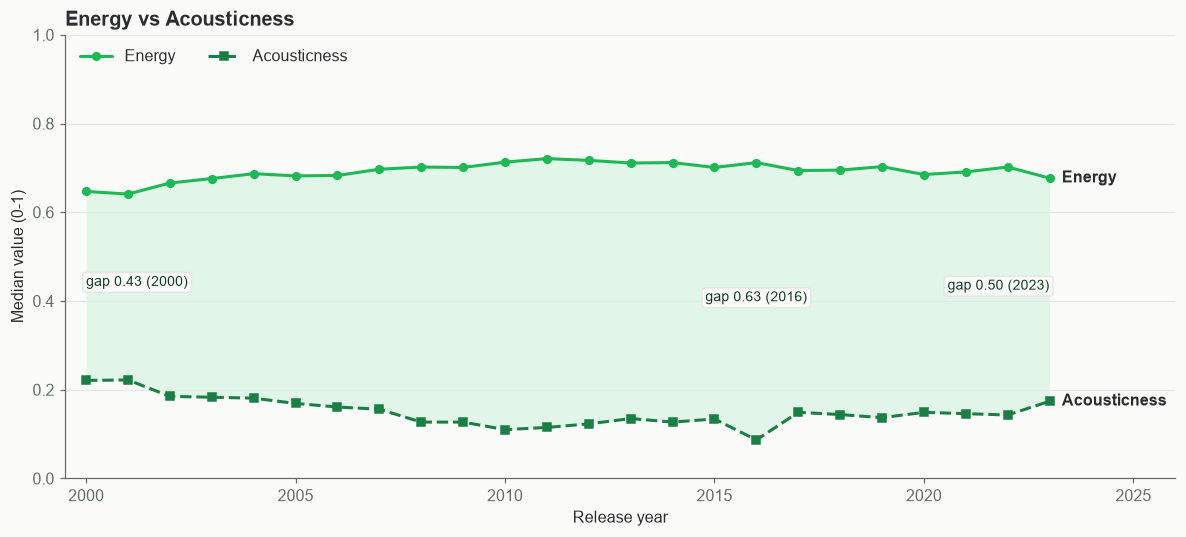

Gap in 2000: 0.426 | peak in 2016: 0.625 | 2023: 0.503


In [97]:
ys = year_summary
gap = ys["median_energy"] - ys["median_acousticness"]
peak_year = int(ys.loc[gap.idxmax(), "year"])

fig, ax = plt.subplots(figsize=(11, 5))

# Shade the gap between the two lines
ax.fill_between(ys["year"], ys["median_acousticness"], ys["median_energy"], color=MINT, alpha=0.7, linewidth=0)
ax.plot(ys["year"], ys["median_energy"], color=SPOTIFY_GREEN, marker="o", markersize=5, label="Energy")
ax.plot(ys["year"], ys["median_acousticness"], color=FOREST, marker="s", markersize=5, linestyle="--", label="Acousticness")

# Direct labels at the right-hand end of each line
last = ys.iloc[-1]
ax.annotate("Energy", (last["year"], last["median_energy"]), xytext=(8, 0),
            textcoords="offset points", va="center", fontweight="bold", color=CHARCOAL)
ax.annotate("Acousticness", (last["year"], last["median_acousticness"]), xytext=(8, 0),
            textcoords="offset points", va="center", fontweight="bold", color=CHARCOAL)

# Annotate the size of the gap at the start, the peak and the end
for yr, align in [(ys["year"].min(), "left"), (peak_year, "center"), (ys["year"].max(), "right")]:
    row = ys[ys["year"] == yr].iloc[0]
    g = row["median_energy"] - row["median_acousticness"]
    mid = (row["median_energy"] + row["median_acousticness"]) / 2
    ax.annotate(f"gap {g:.2f} ({yr})", (yr, mid), ha=align, fontsize=9, color=DEEP_FOREST,
                bbox=dict(boxstyle="round,pad=0.25", fc=BACKGROUND, ec=GRID))

ax.set_ylim(0, 1)
ax.set_xlim(ys["year"].min() - 0.5, ys["year"].max() + 3)
ax.set_xlabel("Release year")
ax.set_ylabel("Median value (0-1)")
ax.set_title("Energy vs Acousticness")
ax.legend(loc="upper left", ncol=2)   # top band of the chart is empty, so nothing is covered
plt.tight_layout()
save_fig(fig, "03_energy_vs_acousticness")
plt.show()

print(f"Gap in {ys['year'].min()}: {gap.iloc[0]:.3f} | peak in {peak_year}: {gap.max():.3f} | {ys['year'].max()}: {gap.iloc[-1]:.3f}")

Across all observed release years, median energy consistently exceeds acousticness, exhibiting no trajectory crossover. Key dynamic trends include:

**2000 – Mid-2010s**: Acousticness declined by approximately 50% alongside a steady rise in energy, reflecting an increased emphasis on synthesized and highly produced audio profiles.

**Late 2010s – 2023(Acoustic Recovery)**: The divergence narrowed slightly as acousticness demonstrated a partial recovery, aligning with the rise of bedroom-pop, lo-fi genres, and acoustic-focused curated streaming playlists.

**Sample Anomaly Note (2016 Peak)**: The 2016 acousticness spike represents an isolated outlier relative to adjacent years. Given the reduced sample density for this specific release year, this variance is attributable to sampling distribution rather than a broad structural shift in production.st both neighbours. That points to *how the data was sampled* more than a real one-year shift.

#### 5.2 Evaluating Common Music Industry Hypotheses

To contextualize temporal trends, three widely cited music industry narratives are tested against the dataset:

* **The Loudness War:** From the 1990s through the 2000s, mastering engineers pushed records ever louder to stand out on radio and CDs, at the cost of dynamic range. Loudness normalisation on streaming platforms (from around the mid-2010s) removed most of the reward for doing so.
* **Track Duration Compression:** The trend toward shorter song durations is frequently linked to streaming monetization mechanics (where tracks monetize at the 30-second mark) and the proliferation of short-form video platforms.
* **Emotional Valence Shifts:** Studies analyzing chart music (e.g., Interiano et al., 2018, Royal Society Open Science) highlight a multi-decade decline in musical "valence" (perceived positivity/happiness) in commercial releases.
Each measure gets **its own small panel and axis**, because loudness (dB), duration (minutes) and valence (0–1) can't share a scale.

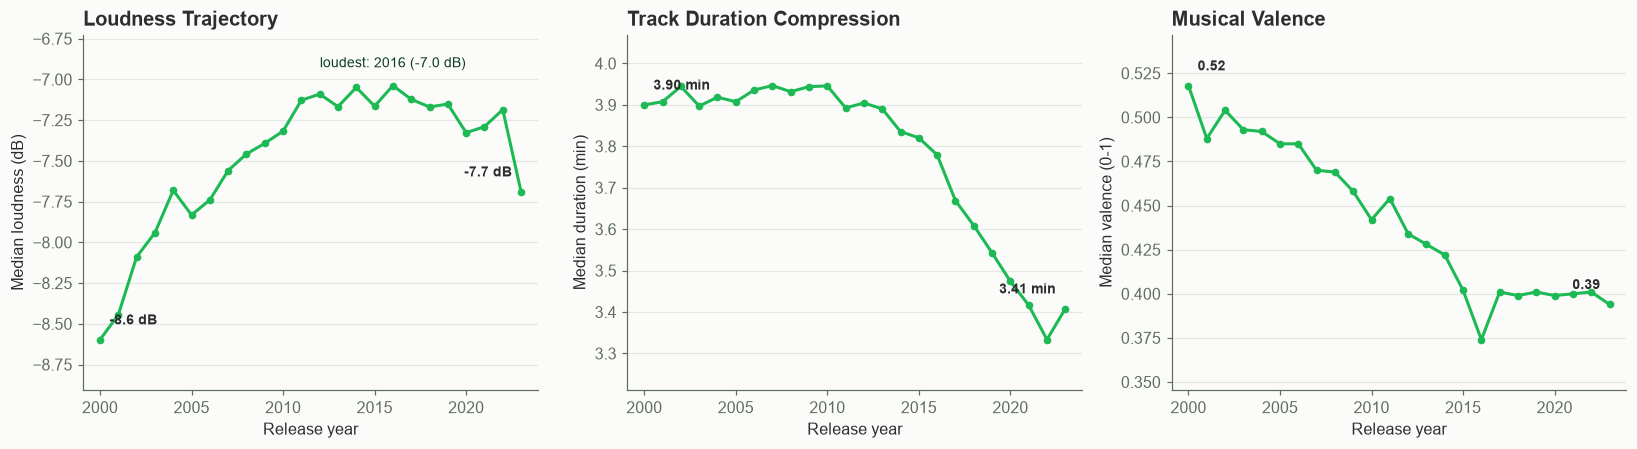

,loudness_db,duration_min,valence
year,,,
2000,-8.60,3.90,0.52
2016,-7.04,3.78,0.37
2023,-7.69,3.41,0.39


In [98]:
trends = clean.groupby("year").agg(
    loudness_db=("loudness", "median"),
    duration_min=("duration_ms", lambda s: s.median() / 60000),
    valence=("valence", "median"),
)

panels = [
    ("loudness_db", "Loudness Trajectory", "Median loudness (dB)", "{:.1f} dB"),
    ("duration_min", "Track Duration Compression", "Median duration (min)", "{:.2f} min"),
    ("valence", "Musical Valence", "Median valence (0-1)", "{:.2f}"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, title, ylabel, fmt) in zip(axes, panels):
    ax.plot(trends.index, trends[col], color=SPOTIFY_GREEN, marker="o", markersize=4)
    # Label the first and last values directly (first label sits right of its point, last sits left)
    for yr, align, dx in [(trends.index.min(), "left", 6), (trends.index.max(), "right", -6)]:
        ax.annotate(fmt.format(trends.loc[yr, col]), (yr, trends.loc[yr, col]),
                    xytext=(dx, 10), textcoords="offset points", ha=align, fontsize=9,
                    fontweight="bold", color=CHARCOAL)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Release year")
    ax.margins(x=0.04, y=0.2)

# Mark the loudest year on the loudness panel (above the peak, where the plot is empty)
loudest = trends["loudness_db"].idxmax()
axes[0].annotate(f"loudest: {loudest} ({trends.loc[loudest, 'loudness_db']:.1f} dB)",
                 (loudest, trends.loc[loudest, "loudness_db"]),
                 xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9, color=DEEP_FOREST)

plt.tight_layout()
save_fig(fig, "04_industry_claims")
plt.show()

trends.loc[[2000, loudest, 2023]].round(2)

## 6. Density Analysis: Resolving Overplotting via Hexbin Maps

A scatter plot of 1.16 million points suffers from **overplotting**: dots pile on top of each other until the busy middle becomes a solid blob. A region holding 50,000 tracks then looks the same as one holding 500, so the chart hides exactly what we want to see: *where most tracks sit*.

A **hexbin** fixes this. It splits the plane into hexagons and colors each one by **how many tracks fall inside**. A **log** color scale keeps both the dense core and the sparse edges visible. It uses all 1.16M tracks, needs no sampling and renders in seconds.

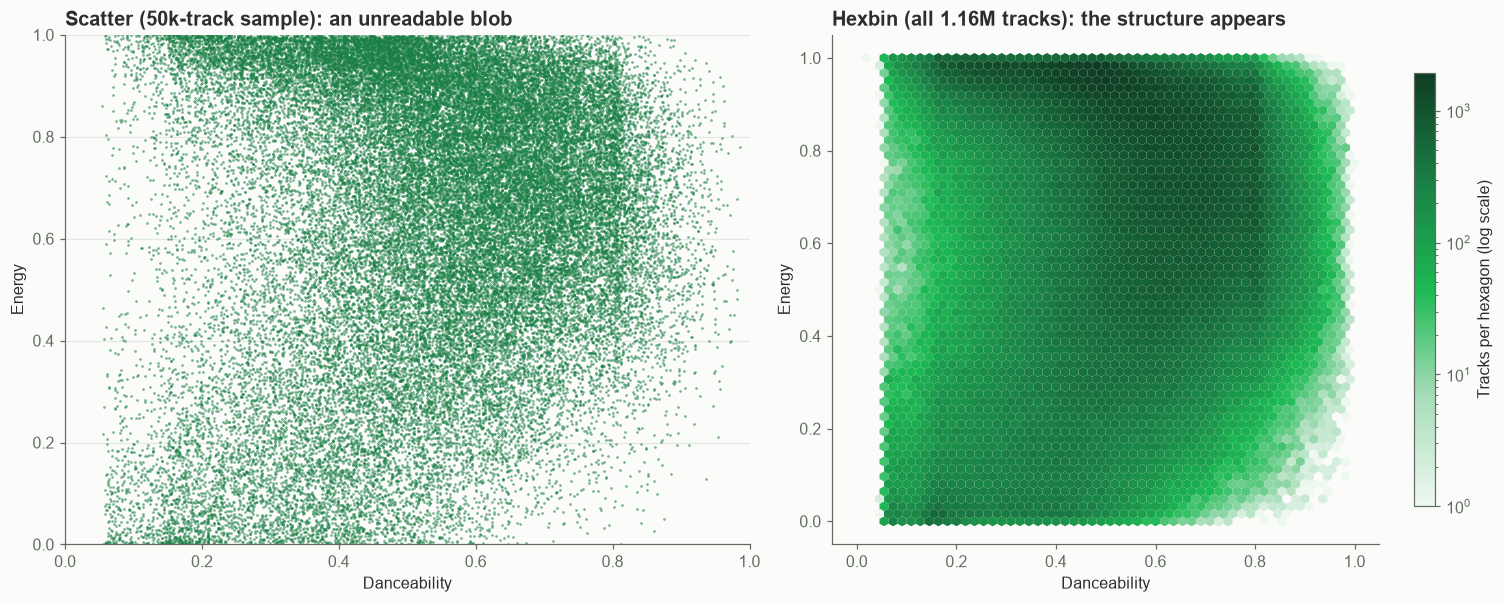

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# Left: what a naive scatter looks like (a random 50k-track sample, fixed seed for reproducibility)
sample = clean.sample(50_000, random_state=42)
axes[0].scatter(sample["danceability"], sample["energy"], s=3, color=FOREST, alpha=0.6, linewidths=0)
axes[0].set_title("Scatter (50k-track sample): an unreadable blob")
axes[0].set_xlabel("Danceability"); axes[0].set_ylabel("Energy")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)

# Right: hexbin of ALL tracks with a log color scale
hb = axes[1].hexbin(clean["danceability"], clean["energy"], gridsize=55, bins="log",
                    cmap=GREEN_SEQUENTIAL, mincnt=1, extent=(0, 1, 0, 1), linewidths=0)
axes[1].set_title(f"Hexbin (all {len(clean)/1e6:.2f}M tracks): the structure appears")
axes[1].set_xlabel("Danceability"); axes[1].set_ylabel("Energy")
axes[1].grid(False)
cbar = fig.colorbar(hb, ax=axes[1], shrink=0.85)
cbar.set_label("Tracks per hexagon (log scale)")

plt.tight_layout()
save_fig(fig, "05_danceability_energy_hexbin")
plt.show()


* The darkest band runs along the **top of the chart: very high energy (~0.8–1.0) at mid danceability (~0.3–0.65)**. This is the loud, driving territory of rock, metal and electronic genres. It continues down into a second dense area at **danceability ~0.55–0.8 and energy ~0.6–0.8**, the groove-based "default" pop and dance track.
* There is a separate **cluster in the low-energy, low-danceability corner** (energy near 0, danceability ~0.1–0.25), where ambient, classical, sleep and piano sit. In the scatter plot it is just a faint smudge.
* The **bottom-right corner is nearly empty**: tracks that are very danceable *and* very low-energy are rare.
* Danceability almost never goes above ~0.95 or below ~0.05, so the full 0–1 range is never used.

## 7. Genre Profiling

### 7.1 The audio signatures of the three most popular genres

**How "most popular" is defined:** genres are ranked by **median popularity in the 2020–2023 era** in `genre_summary.csv`, ignoring any group flagged `small_sample`. The most recent era is the fairest comparison, because popularity is a *current* snapshot and older tracks score lower across every genre.

A **radar chart** suits this comparison: four features on the same 0–1 scale, three genres, and the aim is to compare *shapes*, not read exact values.

In [100]:
RADAR_FEATURES = ["danceability", "energy", "valence", "acousticness"]

recent = genre_summary[(genre_summary["era"] == "2020-2023") & (~genre_summary["small_sample"])]
top3 = recent.sort_values("median_popularity", ascending=False).head(3).reset_index(drop=True)
top3[["genre", "track_count", "median_popularity"] + [f"median_{f}" for f in RADAR_FEATURES]]

,genre,track_count,median_popularity,median_danceability,median_energy,median_valence,median_acousticness
0,pop,1131,66.0,0.638,0.578,0.448,0.2380
1,hip-hop,2909,56.0,0.752,0.632,0.492,0.1040
2,dance,2692,56.0,0.677,0.742,0.481,0.0646


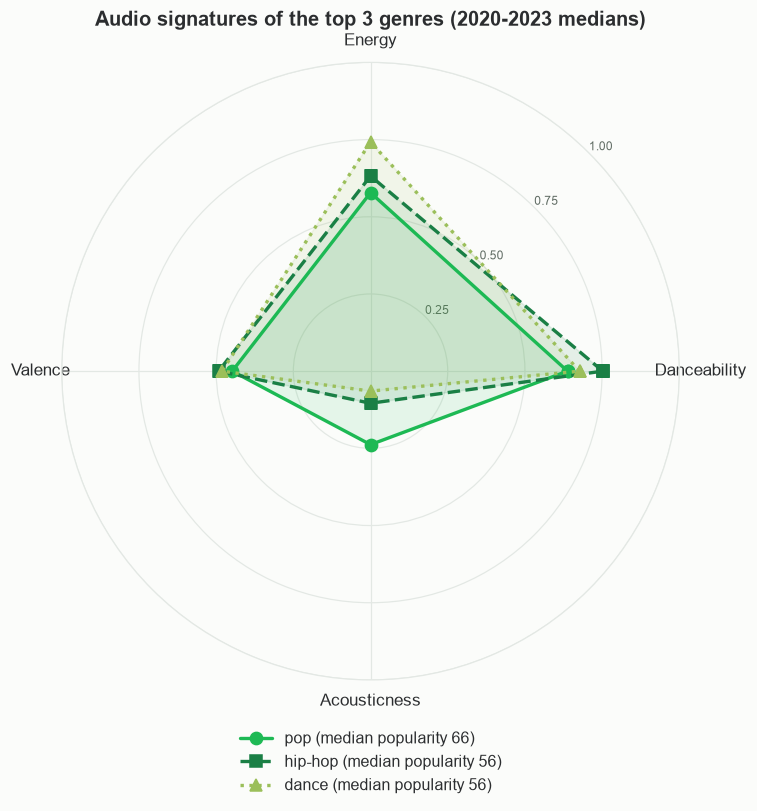

In [101]:
# One angle per feature; repeat the first point at the end to close each shape
angles = np.linspace(0, 2 * np.pi, len(RADAR_FEATURES), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw={"polar": True})
line_styles = ["-", "--", ":"]
markers = ["o", "s", "^"]

for i, row in top3.iterrows():
    values = [row[f"median_{f}"] for f in RADAR_FEATURES]
    values += values[:1]
    label = f"{row['genre']} (median popularity {row['median_popularity']:.0f})"
    ax.plot(angles, values, color=SERIES_COLORS[i], linestyle=line_styles[i],
            marker=markers[i], markersize=8, linewidth=2.2, label=label)
    ax.fill(angles, values, color=SERIES_COLORS[i], alpha=0.10)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([f.capitalize() for f in RADAR_FEATURES], fontsize=11, color=CHARCOAL)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=8, color=MUTED_TEXT)
ax.set_rlabel_position(45)
ax.grid(color=GRID)
ax.spines["polar"].set_color(GRID)
ax.set_facecolor(BACKGROUND)
ax.set_title("Audio signatures of the top 3 genres (2020-2023 medians)", pad=24, loc="center")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=1)
plt.tight_layout()
save_fig(fig, "06_top3_genre_radar")
plt.show()

* All three share the modern "hit" shape: **high danceability, high energy, low acousticness**.
* **Hip-hop** is the most danceable (0.75), the strongest groove of the three.
* **Dance** is the most produced: it has the highest energy (0.74) and almost no acoustic content (0.06).
* **Pop** is the softest and most balanced: it has the lowest energy (0.58) and is by far the most acoustic (0.24), which reflects how many recent pop hits are piano- or guitar-led.
* **Valence is nearly identical** (0.45–0.49). Mood does not separate these genres; energy and acousticness do.

### 7.2 How each genre's sound shifted between eras

The radar chart shows a snapshot. This table shows **movement**: the change in each genre's median from the 2000s to 2020–2023, for the genres with the biggest swing in energy and acousticness.

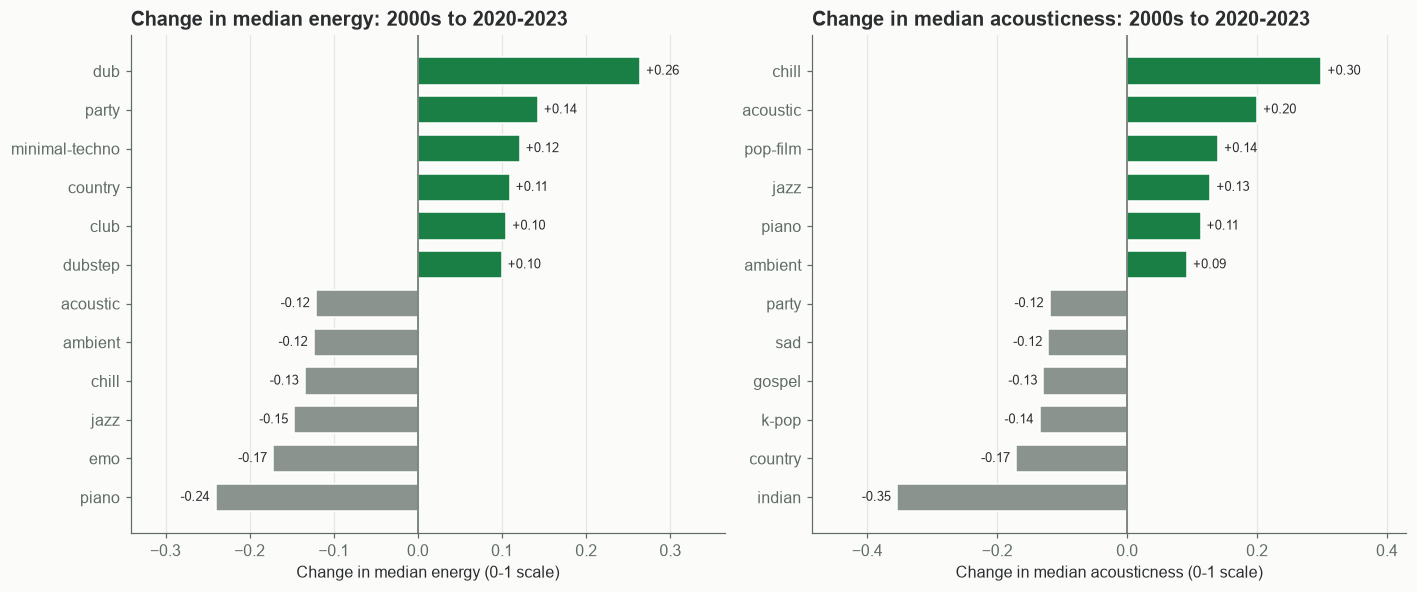

In [102]:
wide = genre_summary[~genre_summary["small_sample"]].pivot(index="genre", columns="era",
                                                          values=["median_energy", "median_acousticness"])
shift = pd.DataFrame({
    "energy_change": wide[("median_energy", "2020-2023")] - wide[("median_energy", "2000s")],
    "acousticness_change": wide[("median_acousticness", "2020-2023")] - wide[("median_acousticness", "2000s")],
}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=False)
for ax, col, title in [(axes[0], "energy_change", "Energy"), (axes[1], "acousticness_change", "Acousticness")]:
    s = shift[col].sort_values()
    picked = pd.concat([s.head(6), s.tail(6)])     # 6 biggest falls and 6 biggest rises
    colors = [FOREST if v > 0 else "#8A938D" for v in picked]
    ax.barh(picked.index, picked.values, color=colors, height=0.7)
    ax.axvline(0, color=MUTED_TEXT, linewidth=1)
    ax.set_title(f"Change in median {title.lower()}: 2000s to 2020-2023")
    ax.set_xlabel(f"Change in median {title.lower()} (0-1 scale)")
    ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
    for y, v in enumerate(picked.values):
        ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                    ha="left" if v > 0 else "right", va="center", fontsize=8.5, color=CHARCOAL)
    ax.margins(x=0.2)

plt.tight_layout()
save_fig(fig, "07_genre_shifts")
plt.show()

Green bars are **rises** and grey bars are **falls**. The overall trend from Section 5 hides big differences between genres:

* **Softer and more organic:** `chill`, `acoustic`, `jazz`, `piano` and `ambient` all lost energy *and* gained acousticness. These are the "calm" genres getting calmer, consistent with the streaming-era boom in focus and relaxation playlists.
* **Harder and more produced:** `dub` gained the most energy (+0.26), followed by `party`, `minimal-techno` and `club`.
* **Big acoustic-to-produced swings:** `indian` (-0.35 acousticness), `country` and `k-pop` moved strongly toward produced sound. `country` is notable for both gaining energy and losing acousticness, so it is becoming more pop-like.

These genre-level swings are a good starting point for the Power BI drill-down.

## 8. Mythbusting: Does Tempo Drive Popularity?

A common belief is that **faster, more upbeat songs perform better**. `src/prepare_data.py` tested this with a Spearman correlation between `tempo` and `popularity`:

| Subset | Tracks | Spearman ρ | p-value |
|---|---|---|---|
| All cleaned tracks | 1,158,536 | -0.0036 | 0.0001 |
| Excluding popularity = 0 | 1,000,578 | **-0.0014** | **0.17** |

**ρ is practically zero in both cases.** The first p-value looks "significant" only because the sample has over a million tracks, so even a meaningless wobble passes the test. Once tracks with no popularity data are excluded, it isn't even statistically significant.

Below I recompute the numbers live and then **show** the result in three ways.

In [103]:
results = []
for name, subset in {"All cleaned tracks": clean,
                     "Excluding popularity = 0": clean[clean["popularity"] > 0]}.items():
    rho, p = stats.spearmanr(subset["tempo"], subset["popularity"])
    results.append({"subset": name, "n_tracks": len(subset), "spearman_rho": round(rho, 4), "p_value": round(p, 4)})
pd.DataFrame(results)

,subset,n_tracks,spearman_rho,p_value
0,All cleaned tracks,1158536,-0.0036,0.0001
1,Excluding popularity = 0,1000578,-0.0014,0.1719


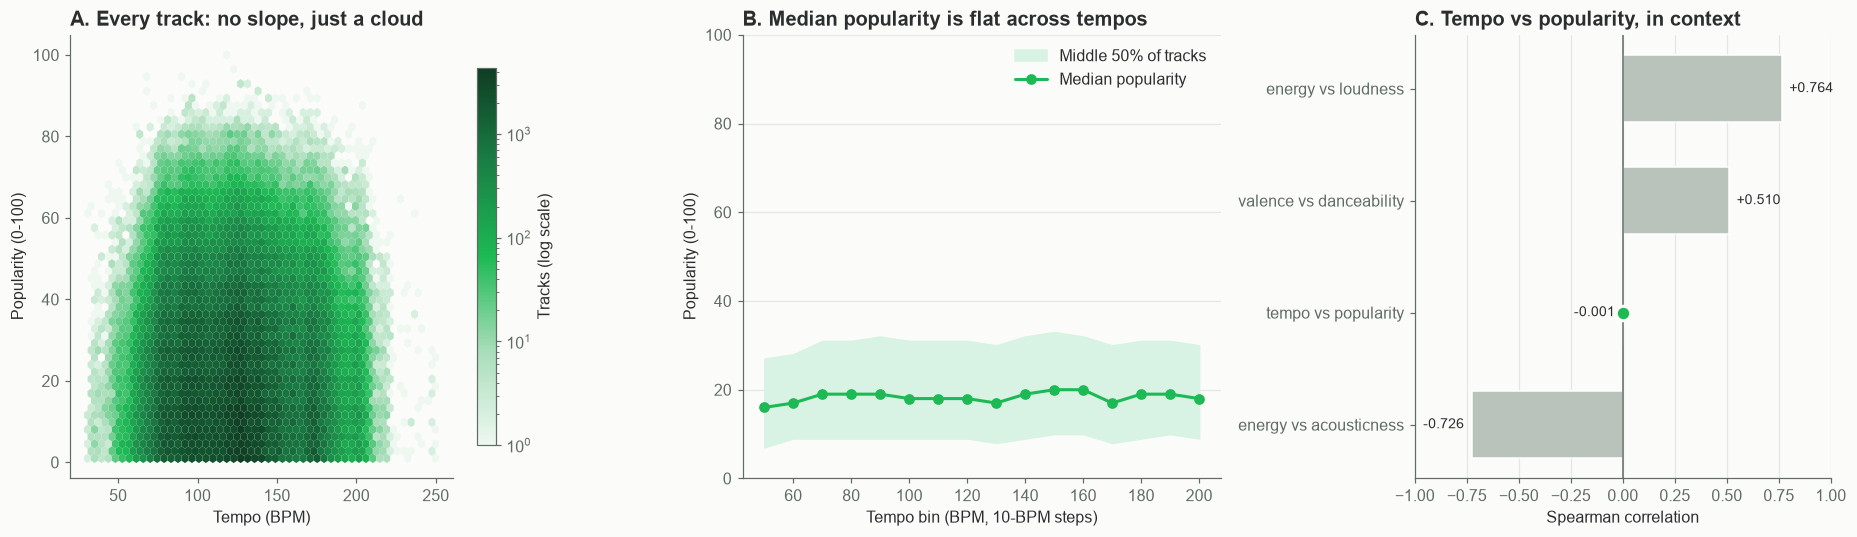

Median popularity ranges only from 16 to 20 across tempo bins 50-210 BPM (each bin >= 1,000 tracks).


In [104]:
popular = clean[clean["popularity"] > 0].copy()

# Group tempo into 10-BPM bins and keep bins with enough tracks for a stable median
popular["tempo_bin"] = (popular["tempo"] // 10 * 10).astype(int)
by_bin = popular.groupby("tempo_bin")["popularity"].agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), tracks="count")
by_bin = by_bin[by_bin["tracks"] >= 1000]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.15, 1.15, 1]})

# Panel A: density of every track
hb = axes[0].hexbin(popular["tempo"], popular["popularity"], gridsize=50, bins="log",
                    cmap=GREEN_SEQUENTIAL, mincnt=1, linewidths=0)
axes[0].set_title("A. Every track: no slope, just a cloud")
axes[0].set_xlabel("Tempo (BPM)"); axes[0].set_ylabel("Popularity (0-100)")
axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], shrink=0.85).set_label("Tracks (log scale)")

# Panel B: median popularity per tempo bin, with the middle 50% shaded
axes[1].fill_between(by_bin.index, by_bin["q25"], by_bin["q75"], color=MINT, label="Middle 50% of tracks")
axes[1].plot(by_bin.index, by_bin["median"], color=SPOTIFY_GREEN, marker="o", markersize=6, label="Median popularity")
axes[1].set_ylim(0, 100)
axes[1].set_title("B. Median popularity is flat across tempos")
axes[1].set_xlabel("Tempo bin (BPM, 10-BPM steps)"); axes[1].set_ylabel("Popularity (0-100)")
axes[1].legend(loc="upper right")

# Panel C: the correlation in context, next to the clearest relationships from Section 4
reference = pd.Series({
    "energy vs acousticness": corr.loc["energy", "acousticness"],
    "energy vs loudness": corr.loc["energy", "loudness"],
    "valence vs danceability": corr.loc["valence", "danceability"],
    "tempo vs popularity": results[1]["spearman_rho"],
}).sort_values()
bar_colors = [SPOTIFY_GREEN if k == "tempo vs popularity" else "#B9C3BC" for k in reference.index]
axes[2].barh(reference.index, reference.values, color=bar_colors, height=0.6)
axes[2].axvline(0, color=MUTED_TEXT, linewidth=1)
# The tempo bar is too small to see, so add a marker at its value to show where it sits
tempo_pos = list(reference.index).index("tempo vs popularity")
axes[2].scatter(reference["tempo vs popularity"], tempo_pos, s=90, color=SPOTIFY_GREEN,
                edgecolor=BACKGROUND, linewidth=2, zorder=3)
axes[2].set_xlim(-1, 1)
axes[2].set_title("C. Tempo vs popularity, in context")
axes[2].set_xlabel("Spearman correlation")
axes[2].grid(axis="x", color=GRID); axes[2].grid(axis="y", visible=False)
for y, v in enumerate(reference.values):
    axes[2].annotate(f"{v:+.3f}", (v, y), xytext=(5 if v >= 0 else -5, 0), textcoords="offset points",
                     ha="left" if v >= 0 else "right", va="center", fontsize=9, color=CHARCOAL)

plt.tight_layout()
save_fig(fig, "08_tempo_vs_popularity")
plt.show()

print(f"Median popularity ranges only from {by_bin['median'].min():.0f} to {by_bin['median'].max():.0f} "
      f"across tempo bins {by_bin.index.min()}-{by_bin.index.max() + 10} BPM (each bin >= 1,000 tracks).")

**Myth busted.**

* **A:** the density cloud of a million tracks has no tilt. Fast and slow songs reach every level of popularity.
* **B:** split into 10-BPM bins, median popularity is almost a flat line, and the middle-50% bands overlap almost completely.
* **C:** next to the relationships that *do* exist in this data (energy vs acousticness and energy vs loudness are strong), tempo vs popularity is a tiny sliver around zero.

**Interpretation:** across the catalogue, tempo tells you nothing useful about how popular a track will be. Popularity depends on things this dataset doesn't measure, such as the artist's existing audience, playlist placement, marketing and timing.

> A Spearman test finds *monotonic* relationships ("more tempo → more/less popularity"). It would miss a "sweet-spot" pattern, but Panel B shows no sweet spot either.

## 9. Key takeaways

1. **The data is clean and fit for purpose.** All required fields are present with no missing values. Only 1,228 rows (0.11%) were removed, all of them failed audio analyses.
2. **Sound became more produced, then eased slightly.** The energy–acousticness gap widened from 2000 into the mid-2010s and narrowed a little afterwards. The lines never cross.
3. **All three industry claims show up in this sample, with nuances.** Loudness rose until the early 2010s and then plateaued and eased. Songs got about half a minute shorter, almost all of it after 2014. Valence (musical "happiness") fell until 2016 and has been flat since.
4. **The most popular genres share a hit template** (danceable, energetic, non-acoustic) but differ in the details: hip-hop is the most danceable, dance the most produced, pop the softest and most acoustic. Their valence is almost identical.
5. **Tempo does not drive popularity.** ρ ≈ 0 with or without zero-popularity tracks, and the binned medians are flat.

### Limitations
* Popularity is a current snapshot, so it favours recent tracks; compare it *within* eras, not across them.
* The dataset is a catalogue sample, not a chart of hits.
* Each track has one genre label; the 2016 and 2023 samples are thinner.
* Correlation is not causation: none of these trends proves *why* sound changed.

### Next steps
* **Power BI:** build an interactive dashboard from `year_summary.csv` and `genre_summary.csv` (era slicer, genre drill-down).
* **Statistical testing:** use Kruskal–Wallis tests to check whether genre audio profiles differ significantly *between eras*.
* **Within-era popularity:** repeat the popularity analysis inside each era to remove the snapshot bias.

*All figures are saved in `reports/figures/`.*